In [21]:
!pip install -q kagglehub

import kagglehub
import os

dataset_path = kagglehub.dataset_download("reubensuju/celeb-df-v2")

print("Dataset downloaded:", dataset_path)
print(os.listdir(dataset_path))

Using Colab cache for faster access to the 'celeb-df-v2' dataset.
Dataset downloaded: /kaggle/input/celeb-df-v2
['YouTube-real', 'Celeb-synthesis', 'Celeb-real', 'List_of_testing_videos.txt']


In [ ]:
!pip -q install kagglehub

import kagglehub
path = kagglehub.dataset_download("reubensuju/celeb-df-v2")
print("Dataset downloaded to:", path)

Using Colab cache for faster access to the 'celeb-df-v2' dataset.
Dataset downloaded to: /kaggle/input/celeb-df-v2


In [22]:
import os


print("Dataset path:", dataset_path)
print("\nTop-level contents:")

for item in os.listdir(dataset_path):
    full_path = os.path.join(dataset_path, item)
    print(item, "—", "folder" if os.path.isdir(full_path) else "file")

Dataset path: /kaggle/input/celeb-df-v2

Top-level contents:
YouTube-real — folder
Celeb-synthesis — folder
Celeb-real — folder
List_of_testing_videos.txt — file


In [ ]:
import os

video_count = 0

for root, dirs, files in os.walk(dataset_path):
    videos = [f for f in files if f.lower().endswith((".mp4", ".avi", ".mov"))]
    if videos:
        print(root, ":", len(videos), "videos")
        video_count += len(videos)

print("\nTotal videos found:", video_count)

/kaggle/input/celeb-df-v2/YouTube-real : 300 videos
/kaggle/input/celeb-df-v2/Celeb-synthesis : 5639 videos
/kaggle/input/celeb-df-v2/Celeb-real : 590 videos

Total videos found: 6529


In [23]:
import os
import pandas as pd



real_folders = ["YouTube-real", "Celeb-real"]
fake_folders = ["Celeb-synthesis"]

records = []

for folder in real_folders:
    folder_path = os.path.join(dataset_path, folder)

    for filename in os.listdir(folder_path):
        if filename.lower().endswith((".mp4", ".avi", ".mov")):
            records.append({
                "path": os.path.join(folder_path, filename),
                "video": filename,
                "label": 0,
                "class": "REAL"
            })

for folder in fake_folders:
    folder_path = os.path.join(dataset_path, folder)

    for filename in os.listdir(folder_path):
        if filename.lower().endswith((".mp4", ".avi", ".mov")):
            records.append({
                "path": os.path.join(folder_path, filename),
                "video": filename,
                "label": 1,
                "class": "FAKE"
            })

df = pd.DataFrame(records)

print("Total videos:", len(df))
print("\nClass counts:")
print(df["class"].value_counts())
display(df.head())

Total videos: 6529

Class counts:
class
FAKE    5639
REAL     890
Name: count, dtype: int64


,path,video,label,class
0,/kaggle/input/celeb-df-v2/YouTube-real/00238.mp4,00238.mp4,0,REAL
1,/kaggle/input/celeb-df-v2/YouTube-real/00152.mp4,00152.mp4,0,REAL
2,/kaggle/input/celeb-df-v2/YouTube-real/00269.mp4,00269.mp4,0,REAL
3,/kaggle/input/celeb-df-v2/YouTube-real/00209.mp4,00209.mp4,0,REAL
4,/kaggle/input/celeb-df-v2/YouTube-real/00297.mp4,00297.mp4,0,REAL


In [ ]:
test_list_path = os.path.join(
    dataset_path, "List_of_testing_videos.txt"
)

with open(test_list_path, "r") as f:
    test_lines = [line.strip() for line in f if line.strip()]

print("Test-list entries:", len(test_lines))
print("First 10 entries:")
print(test_lines[:10])

Test-list entries: 518
First 10 entries:
['1 YouTube-real/00170.mp4', '1 YouTube-real/00208.mp4', '1 YouTube-real/00063.mp4', '1 YouTube-real/00024.mp4', '1 YouTube-real/00021.mp4', '1 YouTube-real/00036.mp4', '1 YouTube-real/00202.mp4', '1 YouTube-real/00236.mp4', '1 YouTube-real/00197.mp4', '1 YouTube-real/00133.mp4']


Create data splits

In [27]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

dataset_path = "/kaggle/input/celeb-df-v2"
test_list_path = os.path.join(
    dataset_path, "List_of_testing_videos.txt"
)

# Read the official test-list paths
with open(test_list_path, "r") as f:
    test_relpaths = {
        line.strip().split(maxsplit=1)[1].replace("\\", "/")
        for line in f
        if line.strip() and len(line.strip().split(maxsplit=1)) == 2
    }

# Create relative paths for matching
df["relative_path"] = df["path"].apply(
    lambda p: os.path.relpath(p, dataset_path).replace("\\", "/")
)

df["split"] = "remaining"
df.loc[df["relative_path"].isin(test_relpaths), "split"] = "test"

# Check that the official test list matched our files
matched = (df["split"] == "test").sum()
print("Official test videos matched:", matched)
print("Test-list entries:", len(test_relpaths))
print("\nOfficial test split class counts:")
print(df[df["split"] == "test"]["class"].value_counts())

# Split remaining videos into train and validation
remaining = df[df["split"] == "remaining"].copy()

train_df, val_df = train_test_split(
    remaining,
    test_size=0.15,
    random_state=42,
    stratify=remaining["label"]
)

train_df = train_df.copy()
val_df = val_df.copy()
test_df = df[df["split"] == "test"].copy()

train_df["split"] = "train"
val_df["split"] = "val"

print("\nTrain:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nClass counts per split:")
for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}")
    print(part["class"].value_counts())

# Save the split manifests
train_df.to_csv("/content/train_videos.csv", index=False)
val_df.to_csv("/content/val_videos.csv", index=False)
test_df.to_csv("/content/test_videos.csv", index=False)

Official test videos matched: 518
Test-list entries: 518

Official test split class counts:
class
FAKE    340
REAL    178
Name: count, dtype: int64

Train: 5109
Validation: 902
Test: 518

Class counts per split:

Train
class
FAKE    4504
REAL     605
Name: count, dtype: int64

Validation
class
FAKE    795
REAL    107
Name: count, dtype: int64

Test
class
FAKE    340
REAL    178
Name: count, dtype: int64


In [ ]:
!pip -q install opencv-python-headless

Frame Extraction

In [28]:
import os
import cv2
import numpy as np
from tqdm.auto import tqdm

FRAME_ROOT = "/content/celebdf_frames"
FRAMES_PER_VIDEO = 5

for split_name, split_df in [
    ("train", train_df),
    ("val", val_df),
    ("test", test_df)
]:
    for _, row in tqdm(
        split_df.iterrows(),
        total=len(split_df),
        desc=f"Extracting {split_name}"
    ):
        video_path = row["path"]
        label_name = row["class"]

        output_dir = os.path.join(
            FRAME_ROOT, split_name, label_name
        )
        os.makedirs(output_dir, exist_ok=True)

        video_id = os.path.splitext(
            os.path.basename(video_path)
        )[0]
        cap = cv2.VideoCapture(video_path)

        if not cap.isOpened():
            print("Could not open:", video_path)
            continue

        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        if total_frames <= 0:
            cap.release()
            continue

        frame_indices = np.linspace(
            0, total_frames - 1,
            min(FRAMES_PER_VIDEO, total_frames),
            dtype=int
        )

        for i, frame_idx in enumerate(frame_indices):
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))
            success, frame = cap.read()

            if not success:
                continue

            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frame = cv2.resize(frame, (224, 224))

            output_path = os.path.join(
                output_dir, f"{video_id}_{i}.jpg"
            )

            cv2.imwrite(
                output_path,
                cv2.cvtColor(frame, cv2.COLOR_RGB2BGR),
                [cv2.IMWRITE_JPEG_QUALITY, 90]
            )

        cap.release()

print("Frame extraction complete!")

Extracting train:   0%|          | 0/5109 [00:00<?, ?it/s]

Extracting val:   0%|          | 0/902 [00:00<?, ?it/s]

Extracting test:   0%|          | 0/518 [00:00<?, ?it/s]

Frame extraction complete!


Frames Verification

In [11]:
for split_name in ["train", "val", "test"]:
    for class_name in ["REAL", "FAKE"]:
        folder = os.path.join(
            FRAME_ROOT, split_name, class_name
        )

        count = (
            len([
                f for f in os.listdir(folder)
                if f.endswith(".jpg")
            ])
            if os.path.isdir(folder)
            else 0
        )

        print(f"{split_name:5} | {class_name:4} | {count} frames")

train | REAL | 0 frames
train | FAKE | 0 frames
val   | REAL | 0 frames
val   | FAKE | 0 frames
test  | REAL | 0 frames
test  | FAKE | 0 frames


In [ ]:
!pip -q install scikit-learn matplotlib

Train EfficientNet-80

In [ ]:
import os
import copy
import torch
import torch.nn as nn
import numpy as np

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

# 1. Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# 2. Image preprocessing
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

FRAME_ROOT = "/content/celebdf_frames"

train_ds = datasets.ImageFolder(
    os.path.join(FRAME_ROOT, "train"),
    transform=train_transform
)
val_ds = datasets.ImageFolder(
    os.path.join(FRAME_ROOT, "val"),
    transform=eval_transform
)

print("Class mapping:", train_ds.class_to_idx)
print("Training frames:", len(train_ds))
print("Validation frames:", len(val_ds))

# 3. Class-weighted loss
# ImageFolder sorts alphabetically: FAKE=0, REAL=1
class_counts = np.bincount(train_ds.targets)
class_weights = len(train_ds) / (
    len(class_counts) * class_counts
)
class_weights = torch.tensor(
    class_weights, dtype=torch.float32, device=device
)

print("Class counts [FAKE, REAL]:", class_counts)
print("Class weights:", class_weights.tolist())

# 4. Data loaders
train_loader = DataLoader(
    train_ds, batch_size=32, shuffle=True,
    num_workers=2, pin_memory=(device.type == "cuda")
)
val_loader = DataLoader(
    val_ds, batch_size=32, shuffle=False,
    num_workers=2, pin_memory=(device.type == "cuda")
)

# 5. Pretrained EfficientNet-B0
weights = models.EfficientNet_B0_Weights.DEFAULT
model = models.efficientnet_b0(weights=weights)

model.classifier[1] = nn.Linear(
    model.classifier[1].in_features, 2
)
model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=1e-4, weight_decay=1e-4
)

# 6. Training and validation
EPOCHS = 10
best_val_loss = float("inf")
best_state = None

for epoch in range(EPOCHS):
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * images.size(0)
        train_correct += (
            outputs.argmax(1) == labels
        ).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_correct += (
                outputs.argmax(1) == labels
            ).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())

# Restore best validation checkpoint
model.load_state_dict(best_state)

torch.save({
    "model_state_dict": model.state_dict(),
    "class_to_idx": train_ds.class_to_idx,
    "architecture": "efficientnet_b0"
}, "/content/celebdf_efficientnet_b0.pth")

print("Best model saved to /content/celebdf_efficientnet_b0.pth")

Using device: cuda
Class mapping: {'FAKE': 0, 'REAL': 1}
Training frames: 25541
Validation frames: 4510
Class counts [FAKE, REAL]: [22520  3021]
Class weights: [0.5670737028121948, 4.227242469787598]
Epoch 1/10 | Train Loss: 0.4713 | Train Acc: 0.7822 | Val Loss: 0.4538 | Val Acc: 0.7809
Epoch 2/10 | Train Loss: 0.2807 | Train Acc: 0.8884 | Val Loss: 0.2896 | Val Acc: 0.8738
Epoch 3/10 | Train Loss: 0.2195 | Train Acc: 0.9125 | Val Loss: 0.2930 | Val Acc: 0.8765
Epoch 4/10 | Train Loss: 0.1692 | Train Acc: 0.9366 | Val Loss: 0.2625 | Val Acc: 0.8922
Epoch 5/10 | Train Loss: 0.1433 | Train Acc: 0.9428 | Val Loss: 0.2144 | Val Acc: 0.9206
Epoch 6/10 | Train Loss: 0.1255 | Train Acc: 0.9507 | Val Loss: 0.2225 | Val Acc: 0.9282
Epoch 7/10 | Train Loss: 0.1058 | Train Acc: 0.9601 | Val Loss: 0.2109 | Val Acc: 0.9277
Epoch 8/10 | Train Loss: 0.0975 | Train Acc: 0.9622 | Val Loss: 0.2221 | Val Acc: 0.9275
Epoch 9/10 | Train Loss: 0.0835 | Train Acc: 0.9673 | Val Loss: 0.2708 | Val Acc: 0.9069

Confusion Metrix


In [ ]:
test_ds = datasets.ImageFolder(
    os.path.join(FRAME_ROOT, "test"),
    transform=eval_transform
)

test_loader = DataLoader(
    test_ds, batch_size=32, shuffle=False,
    num_workers=2
)

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        predictions = outputs.argmax(1).cpu().numpy()

        all_preds.extend(predictions)
        all_labels.extend(labels.numpy())

print("Test Accuracy:", accuracy_score(all_labels, all_preds))
print("Precision:", precision_score(
    all_labels, all_preds, pos_label=test_ds.class_to_idx["FAKE"]
))
print("Recall:", recall_score(
    all_labels, all_preds, pos_label=test_ds.class_to_idx["FAKE"]
))
print("F1 Score:", f1_score(
    all_labels, all_preds, pos_label=test_ds.class_to_idx["FAKE"]
))

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_preds,
    target_names=[
        name for name, idx in sorted(
            test_ds.class_to_idx.items(), key=lambda item: item[1]
        )
    ]
))

print("Confusion Matrix:")
print(confusion_matrix(all_labels, all_preds))

NameError: name 'datasets' is not defined

Import model and testing for myself

In [ ]:

import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
import cv2
import numpy as np
from google.colab import files

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

# Rebuild the same architecture used during training
model = models.efficientnet_b0(weights=None)
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features, 2
)

# Load trained weights
checkpoint = torch.load(
    "/content/celebdf_efficientnet_b0.pth",
    map_location=device
)

# Support either a plain state_dict or a checkpoint dictionary
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    checkpoint = checkpoint["model_state_dict"]

model.load_state_dict(checkpoint)
model = model.to(device)
model.eval()

# Must match the preprocessing used during training
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Model loaded successfully!")


Using: cuda


FileNotFoundError: [Errno 2] No such file or directory: '/content/celebdf_efficientnet_b0.pth'

In [ ]:

# Upload a video
uploaded = files.upload()
video_path = next(iter(uploaded.keys()))

def predict_video(video_path, num_frames=20):
    cap = cv2.VideoCapture(video_path)

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total_frames <= 0:
        cap.release()
        raise ValueError("Could not read this video.")

    # Sample frames across the entire video
    frame_indices = np.linspace(
        0, total_frames - 1,
        min(num_frames, total_frames),
        dtype=int
    )

    fake_probs = []

    for frame_index in frame_indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_index))
        success, frame = cap.read()

        if not success:
            continue

        # OpenCV uses BGR; the model expects RGB
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        image = Image.fromarray(frame)
        image_tensor = transform(image).unsqueeze(0).to(device)

        with torch.no_grad():
            logits = model(image_tensor)
            probabilities = torch.softmax(logits, dim=1)

        # Training class order: FAKE=0, REAL=1
        fake_probs.append(probabilities[0, 0].item())

    cap.release()

    if not fake_probs:
        raise ValueError("No readable frames were found.")

    avg_fake = float(np.mean(fake_probs))
    avg_real = 1.0 - avg_fake

    print(f"Frames analyzed: {len(fake_probs)}")
    print(f"Average FAKE score: {avg_fake:.2%}")
    print(f"Average REAL score: {avg_real:.2%}")

    if avg_fake >= 0.5:
        print("\nPrediction: FAKE")
    else:
        print("\nPrediction: REAL")

    return avg_fake

fake_score = predict_video(video_path)


Saving deepfake.mp4 to deepfake.mp4


NameError: name 'transform' is not defined

**-------------CNN---------------**

In [10]:
FRAME_ROOT = "/content/celebdf_frames"

In [29]:
import os

print("FRAME_ROOT:", FRAME_ROOT)
print("Does FRAME_ROOT exist?", os.path.exists(FRAME_ROOT))

print("\nFolders inside /content:")

for item in os.listdir("/content"):
    print(item)

FRAME_ROOT: /content/celebdf_frames
Does FRAME_ROOT exist? True

Folders inside /content:
.config
celebdf_frames
test_videos.csv
train_videos.csv
val_videos.csv
sample_data


In [8]:
for folder in ["train", "val", "test"]:

    path = os.path.join(FRAME_ROOT, folder)

    print(folder, ":", os.path.exists(path))

    if os.path.exists(path):
        print("Contents:", os.listdir(path))

train : False
val : False
test : False


In [30]:

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import copy
import os

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

cnn_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("CNN Device:", cnn_device)

cnn_train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

cnn_eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

cnn_train_ds = datasets.ImageFolder(
    os.path.join(FRAME_ROOT, "train"),
    transform=cnn_train_transform
)

cnn_val_ds = datasets.ImageFolder(
    os.path.join(FRAME_ROOT, "val"),
    transform=cnn_eval_transform
)

cnn_test_ds = datasets.ImageFolder(
    os.path.join(FRAME_ROOT, "test"),
    transform=cnn_eval_transform
)

print("Class Mapping:", cnn_train_ds.class_to_idx)
print("Training Frames:", len(cnn_train_ds))
print("Validation Frames:", len(cnn_val_ds))
print("Testing Frames:", len(cnn_test_ds))

cnn_train_loader = DataLoader(
    cnn_train_ds,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

cnn_val_loader = DataLoader(
    cnn_val_ds,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

cnn_test_loader = DataLoader(
    cnn_test_ds,
    batch_size=32,
    shuffle=False,
    num_workers=2
)


CNN Device: cuda
Class Mapping: {'FAKE': 0, 'REAL': 1}
Training Frames: 25541
Validation Frames: 4510
Testing Frames: 2590


**CUSTOM CNN ARCHITECTURE**

In [31]:

class DeepfakeCNN(nn.Module):

    def __init__(self):
        super(DeepfakeCNN, self).__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


cnn_model = DeepfakeCNN().to(cnn_device)

print(cnn_model)


DeepfakeCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, aff

**TRAINING CNN**

In [32]:

class_counts = np.bincount(cnn_train_ds.targets)

cnn_class_weights = len(cnn_train_ds) / (
    len(class_counts) * class_counts
)

cnn_class_weights = torch.tensor(
    cnn_class_weights,
    dtype=torch.float32
).to(cnn_device)

cnn_criterion = nn.CrossEntropyLoss(
    weight=cnn_class_weights
)

cnn_optimizer = optim.Adam(
    cnn_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

EPOCHS = 15
PATIENCE = 4

best_val_loss = float("inf")
patience_counter = 0

cnn_train_losses = []
cnn_val_losses = []
cnn_train_accuracies = []
cnn_val_accuracies = []

for epoch in range(EPOCHS):

    cnn_model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in cnn_train_loader:

        images = images.to(cnn_device)
        labels = labels.to(cnn_device)

        cnn_optimizer.zero_grad()

        outputs = cnn_model(images)
        loss = cnn_criterion(outputs, labels)

        loss.backward()
        cnn_optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = correct / total

    cnn_model.eval()

    val_running_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in cnn_val_loader:

            images = images.to(cnn_device)
            labels = labels.to(cnn_device)

            outputs = cnn_model(images)
            loss = cnn_criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = val_correct / val_total

    cnn_train_losses.append(train_loss)
    cnn_val_losses.append(val_loss)

    cnn_train_accuracies.append(train_accuracy)
    cnn_val_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        patience_counter = 0

        torch.save(
            cnn_model.state_dict(),
            "/content/deepfake_cnn.pth"
        )

    else:

        patience_counter += 1

    if patience_counter >= PATIENCE:

        print("Early stopping activated!")
        break


cnn_model.load_state_dict(
    torch.load(
        "/content/deepfake_cnn.pth",
        map_location=cnn_device
    )
)

print("Best CNN model loaded successfully!")


Epoch 1/15 | Train Loss: 0.6857 | Train Accuracy: 0.7484 | Val Loss: 0.6457 | Val Accuracy: 0.7512
Epoch 2/15 | Train Loss: 0.6630 | Train Accuracy: 0.7678 | Val Loss: 0.6027 | Val Accuracy: 0.8548
Epoch 3/15 | Train Loss: 0.6355 | Train Accuracy: 0.8473 | Val Loss: 0.5635 | Val Accuracy: 0.8543
Epoch 4/15 | Train Loss: 0.6293 | Train Accuracy: 0.8728 | Val Loss: 0.5993 | Val Accuracy: 0.8838
Epoch 5/15 | Train Loss: 0.6242 | Train Accuracy: 0.8642 | Val Loss: 0.6125 | Val Accuracy: 0.8202
Epoch 6/15 | Train Loss: 0.6207 | Train Accuracy: 0.8712 | Val Loss: 0.5823 | Val Accuracy: 0.8738
Epoch 7/15 | Train Loss: 0.6208 | Train Accuracy: 0.8715 | Val Loss: 0.6024 | Val Accuracy: 0.8020
Early stopping activated!
Best CNN model loaded successfully!


**Plotting CNN**

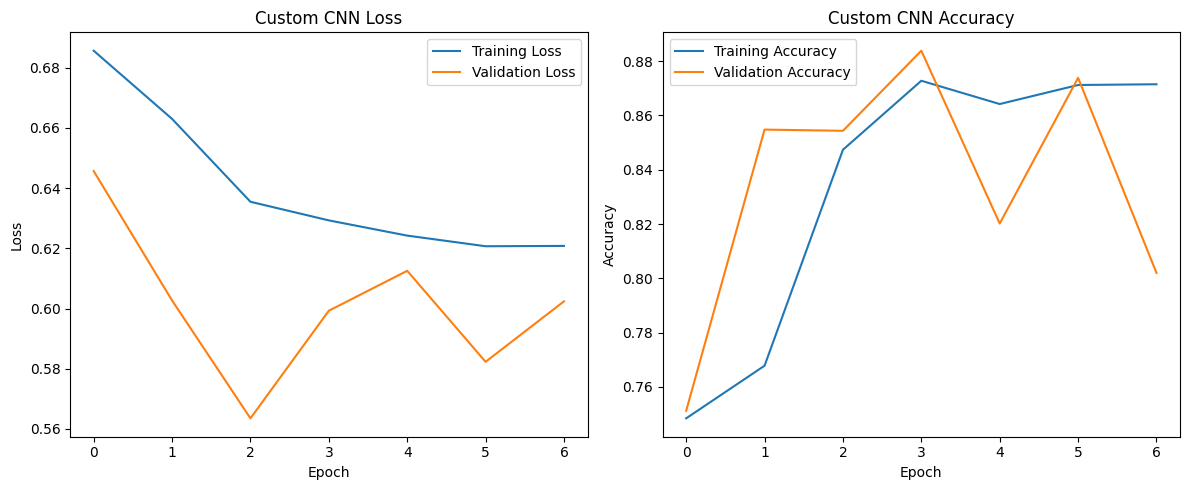

In [33]:

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(cnn_train_losses, label="Training Loss")
plt.plot(cnn_val_losses, label="Validation Loss")

plt.title("Custom CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(cnn_train_accuracies, label="Training Accuracy")
plt.plot(cnn_val_accuracies, label="Validation Accuracy")

plt.title("Custom CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()


Evaluating CNN on Official Test Dataset

CNN Test Accuracy: 0.694980694980695
CNN Fake Precision: 0.6978260869565217
CNN Fake Recall: 0.9441176470588235
CNN Fake F1 Score: 0.8025

CNN Classification Report:
              precision    recall  f1-score   support

        FAKE       0.70      0.94      0.80      1700
        REAL       0.67      0.22      0.33       890

    accuracy                           0.69      2590
   macro avg       0.69      0.58      0.57      2590
weighted avg       0.69      0.69      0.64      2590



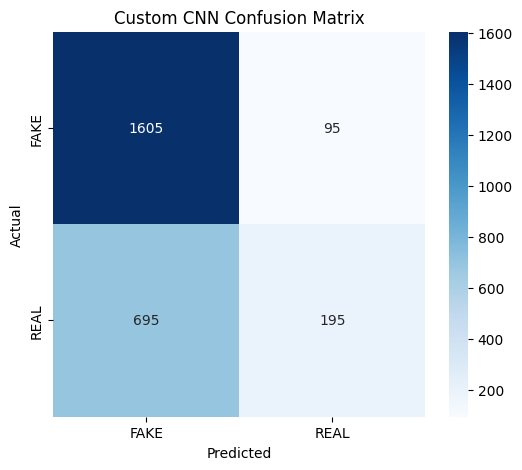

In [34]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import seaborn as sns

cnn_model.eval()

cnn_all_preds = []
cnn_all_labels = []

with torch.no_grad():

    for images, labels in cnn_test_loader:

        images = images.to(cnn_device)

        outputs = cnn_model(images)

        predictions = outputs.argmax(1).cpu().numpy()

        cnn_all_preds.extend(predictions)
        cnn_all_labels.extend(labels.numpy())


cnn_fake_label = cnn_test_ds.class_to_idx["FAKE"]

print("CNN Test Accuracy:",
      accuracy_score(cnn_all_labels, cnn_all_preds))

print("CNN Fake Precision:",
      precision_score(
          cnn_all_labels,
          cnn_all_preds,
          pos_label=cnn_fake_label,
          zero_division=0
      ))

print("CNN Fake Recall:",
      recall_score(
          cnn_all_labels,
          cnn_all_preds,
          pos_label=cnn_fake_label,
          zero_division=0
      ))

print("CNN Fake F1 Score:",
      f1_score(
          cnn_all_labels,
          cnn_all_preds,
          pos_label=cnn_fake_label,
          zero_division=0
      ))

print("\nCNN Classification Report:")

print(classification_report(
    cnn_all_labels,
    cnn_all_preds,
    target_names=["FAKE", "REAL"],
    zero_division=0
))

cnn_cm = confusion_matrix(
    cnn_all_labels,
    cnn_all_preds
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cnn_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["FAKE", "REAL"],
    yticklabels=["FAKE", "REAL"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Custom CNN Confusion Matrix")

plt.show()


Evaluating at video level

In [35]:

import cv2
from PIL import Image

def cnn_video_fake_score(video_path, num_frames=20):

    cap = cv2.VideoCapture(video_path)

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        raise ValueError("Could not read video.")

    indices = np.linspace(
        0,
        total_frames - 1,
        min(num_frames, total_frames),
        dtype=int
    )

    fake_probs = []

    cnn_model.eval()

    for index in indices:

        cap.set(cv2.CAP_PROP_POS_FRAMES, int(index))

        success, frame = cap.read()

        if not success:
            continue

        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        image = Image.fromarray(frame)

        tensor = cnn_eval_transform(image)
        tensor = tensor.unsqueeze(0).to(cnn_device)

        with torch.no_grad():

            output = cnn_model(tensor)

            probability = torch.softmax(output, dim=1)

        fake_probs.append(probability[0, 0].item())

    cap.release()

    if not fake_probs:
        raise ValueError("No readable frames.")

    return float(np.mean(fake_probs))


cnn_video_true = []
cnn_video_preds = []

for _, row in test_df.iterrows():

    score = cnn_video_fake_score(row["path"])

    actual = cnn_train_ds.class_to_idx[row["class"]]

    predicted = 0 if score >= 0.5 else 1

    cnn_video_true.append(actual)
    cnn_video_preds.append(predicted)


print("CNN Video Accuracy:",
      accuracy_score(cnn_video_true, cnn_video_preds))

print("\nCNN Video Classification Report:")

print(classification_report(
    cnn_video_true,
    cnn_video_preds,
    target_names=["FAKE", "REAL"],
    zero_division=0
))

print("CNN Video Confusion Matrix:")

print(confusion_matrix(cnn_video_true, cnn_video_preds))


CNN Video Accuracy: 0.6911196911196911

CNN Video Classification Report:
              precision    recall  f1-score   support

        FAKE       0.69      0.96      0.80       340
        REAL       0.69      0.19      0.29       178

    accuracy                           0.69       518
   macro avg       0.69      0.57      0.55       518
weighted avg       0.69      0.69      0.63       518

CNN Video Confusion Matrix:
[[325  15]
 [145  33]]


Image Prediction

In [36]:

from google.colab import files
from PIL import Image

def predict_cnn_image(image_path):

    image = Image.open(image_path).convert("RGB")

    tensor = cnn_eval_transform(image)
    tensor = tensor.unsqueeze(0).to(cnn_device)

    cnn_model.eval()

    with torch.no_grad():

        output = cnn_model(tensor)

        probabilities = torch.softmax(output, dim=1)

    fake_score = probabilities[0, 0].item()
    real_score = probabilities[0, 1].item()

    prediction = "FAKE" if fake_score >= real_score else "REAL"

    print("CNN Prediction:", prediction)
    print("Fake Score:", f"{fake_score:.2%}")
    print("Real Score:", f"{real_score:.2%}")


cnn_uploaded_images = files.upload()

for filename in cnn_uploaded_images:
    predict_cnn_image(filename)


Video Prediction

In [ ]:

def predict_cnn_video(video_path):

    fake_score = cnn_video_fake_score(video_path)

    real_score = 1 - fake_score

    prediction = "FAKE" if fake_score >= 0.5 else "REAL"

    print("CNN Prediction:", prediction)
    print("Fake Score:", f"{fake_score:.2%}")
    print("Real Score:", f"{real_score:.2%}")


cnn_uploaded_videos = files.upload()

for filename in cnn_uploaded_videos:

    if filename.lower().endswith((".mp4", ".avi", ".mov")):
        predict_cnn_video(filename)

    else:
        print("Please upload a video file.")
